In [21]:
# import
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import os
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
    PrecisionRecallDisplay
)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")


In [22]:
# load cleaned data
CSV_PATH = "../data/processed/telco_cleaned.csv"

df = pd.read_csv(CSV_PATH)

print("Ukuran data:", df.shape)
display(df.head())
display(df.info())


Ukuran data: (7043, 27)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,PaymentMethod,MonthlyCharges,TotalCharges,Churn,ChurnBinary,TenureGroup,NumAdditionalServices,NumTotalServices,HasLongTermContract,MonthlyChargeGroup
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,Electronic check,29.85,29.85,No,0,0-12,1,2,0,Q1
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Mailed check,56.95,1889.50,No,0,25-48,2,4,1,Q2
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,Mailed check,53.85,108.15,Yes,1,0-12,2,4,0,Q2
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Bank transfer (automatic),42.30,1840.75,No,0,25-48,3,4,1,Q2
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,Electronic check,70.70,151.65,Yes,1,0-12,0,2,0,Q3


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 27 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   customerID             7043 non-null   str    
 1   gender                 7043 non-null   str    
 2   SeniorCitizen          7043 non-null   int64  
 3   Partner                7043 non-null   str    
 4   Dependents             7043 non-null   str    
 5   tenure                 7043 non-null   int64  
 6   PhoneService           7043 non-null   str    
 7   MultipleLines          7043 non-null   str    
 8   InternetService        7043 non-null   str    
 9   OnlineSecurity         7043 non-null   str    
 10  OnlineBackup           7043 non-null   str    
 11  DeviceProtection       7043 non-null   str    
 12  TechSupport            7043 non-null   str    
 13  StreamingTV            7043 non-null   str    
 14  StreamingMovies        7043 non-null   str    
 15  Contract       

None

In [23]:
# pengelompokan kolom
TARGET = "Churn"

if TARGET not in df.columns:
    raise ValueError(f"Kolom target '{TARGET}' tidak ditemukan. Periksa nama kolom CSV.")

# Buang baris dengan target kosong
df = df.dropna(subset=[TARGET]).copy()

# Konversi target menjadi 0 = No (non-churn), 1 = Yes (churn)
target_values = set(df[TARGET].astype(str).str.strip().unique())
if target_values.issubset({"Yes", "No"}):
    y = df[TARGET].astype(str).str.strip().map({"No": 0, "Yes": 1})
elif target_values.issubset({"0", "1"}):
    y = df[TARGET].astype(int)
else:
    raise ValueError(f"Format target tidak dikenali: {target_values}. Harapkan Yes/No atau 0/1.")

X = df.drop(columns=[TARGET]).copy()

# Hapus identifier
X = X.drop(columns=["customerID"], errors="ignore")

# Hapus kolom copy Churn
X = X.drop(columns=["ChurnBinary"], errors="ignore")

# lihat pesentase data Churn dan non-churn
print("Jumlah fitur awal:", X.shape[1])
print("Distribusi target:")
display(y.value_counts().rename(index={0: "Non-churn", 1: "Churn"}).to_frame("Jumlah"))
display((y.value_counts(normalize=True) * 100).rename(index={0: "Non-churn", 1: "Churn"}).to_frame("Persentase (%)"))


Jumlah fitur awal: 24
Distribusi target:


,Jumlah
Churn,
Non-churn,5174
Churn,1869


,Persentase (%)
Churn,
Non-churn,73.463013
Churn,26.536987


In [24]:
# train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"Training set: {X_train.shape[0]} baris ({X_train.shape[0]/len(X):.1%})")
print(f"Testing set : {X_test.shape[0]} baris ({X_test.shape[0]/len(X):.1%})")

print("\\nDistribusi target training:")
display(y_train.value_counts(normalize=True).rename(index={0: "Non-churn", 1: "Churn"}))
print("Distribusi target testing:")
display(y_test.value_counts(normalize=True).rename(index={0: "Non-churn", 1: "Churn"}))


Training set: 5634 baris (80.0%)
Testing set : 1409 baris (20.0%)
\nDistribusi target training:


Churn
Non-churn    0.734647
Churn        0.265353
Name: proportion, dtype: float64

Distribusi target testing:


Churn
Non-churn    0.734564
Churn        0.265436
Name: proportion, dtype: float64

In [25]:
# pemisahan fitur numerik dan kategorikal
# numerik: standard scaler
# kategorikal: one-hot encoding

# perhatikan SeniorCitizen isinya 0 atau 1, sehingga termasuk numerik
# padahal seharusnya kategorikal
binary_categorical_features = ["SeniorCitizen"]
for col in binary_categorical_features:
    if col in X_train.columns:
        X_train[col] = X_train[col].map({0: "No", 1: "Yes"})
        X_test[col] = X_test[col].map({0: "No", 1: "Yes"})

numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Fitur numerik:", numeric_features)
print("Fitur kategorikal:", categorical_features)


Fitur numerik: ['tenure', 'MonthlyCharges', 'TotalCharges', 'NumAdditionalServices', 'NumTotalServices', 'HasLongTermContract']
Fitur kategorikal: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TenureGroup', 'MonthlyChargeGroup']


senior citizens harusnya kategorical?

In [26]:
# definisi model dan hyperparameter grid
# model dioptimasi dengan metrik utama F1-score
# note: class_weight juga ikut dituning
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

model_grids = {
    "Logistic Regression": {
        "estimator": LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),
        "params": {
            "model__C": [0.01, 0.1, 1, 10],
            "model__solver": ["liblinear"],
            "model__class_weight": [None, "balanced"]
        }
    },
    "Decision Tree": {
        "estimator": DecisionTreeClassifier(random_state=RANDOM_STATE),
        "params": {
            "model__criterion": ["gini", "entropy"],
            "model__max_depth": [None, 5, 10, 20],
            "model__min_samples_split": [2, 10, 20],
            "model__min_samples_leaf": [1, 5, 10],
            "model__class_weight": [None, "balanced"]
        }
    },
    "Random Forest": {
        "estimator": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
        "params": {
            "model__n_estimators": [200, 400],
            "model__max_depth": [None, 10, 20],
            "model__min_samples_split": [2, 10],
            "model__min_samples_leaf": [1, 5],
            "model__max_features": ["sqrt", 0.8],
            "model__class_weight": [None, "balanced"]
        }
    }
}


In [28]:
best_estimators = {}
cv_results = []

for model_name, config in model_grids.items():
    print(f"\n===== Tuning: {model_name} =====")

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", config["estimator"])
    ])

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=config["params"],
        scoring="f1",
        cv=cv,
        n_jobs=-1,
        refit=True,
        verbose=1,
        return_train_score=True
    )

    grid.fit(X_train, y_train)
    best_estimators[model_name] = grid.best_estimator_

    # Save the best model
    filename = model_name.lower().replace(" ", "_") + ".joblib"
    joblib.dump(grid.best_estimator_, "../model/" + str(filename))

    cv_results.append({
        "Model": model_name,
        "Best CV F1": grid.best_score_,
        "Best Parameters": grid.best_params_
    })

    print("Best CV F1:", round(grid.best_score_, 4))
    print("Best parameters:", grid.best_params_)

cv_results_df = pd.DataFrame(cv_results)
display(cv_results_df[["Model", "Best CV F1", "Best Parameters"]])



===== Tuning: Logistic Regression =====
Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best CV F1: 0.6275
Best parameters: {'model__C': 10, 'model__class_weight': 'balanced', 'model__solver': 'liblinear'}

===== Tuning: Decision Tree =====
Fitting 5 folds for each of 144 candidates, totalling 720 fits
Best CV F1: 0.6172
Best parameters: {'model__class_weight': 'balanced', 'model__criterion': 'gini', 'model__max_depth': 5, 'model__min_samples_leaf': 10, 'model__min_samples_split': 2}

===== Tuning: Random Forest =====
Fitting 5 folds for each of 96 candidates, totalling 480 fits
Best CV F1: 0.6352
Best parameters: {'model__class_weight': 'balanced', 'model__max_depth': 10, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 5, 'model__min_samples_split': 2, 'model__n_estimators': 200}


,Model,Best CV F1,Best Parameters
0,Logistic Regression,0.627530,"{'model__C': 10, 'model__class_weight': 'balan..."
1,Decision Tree,0.617168,"{'model__class_weight': 'balanced', 'model__cr..."
2,Random Forest,0.635216,"{'model__class_weight': 'balanced', 'model__ma..."


In [ ]:
# load the best models
# model_names = [
#     "Logistic Regression",
#     "Decision Tree",sss
#     "Random Forest"
# ]

# best_estimators = {}

# for model_name in model_names:
#     filename = model_name.lower().replace(" ", "_") + ".joblib"
#     filepath = os.path.join("model", filename)

#     best_estimators[model_name] = joblib.load(filepath)

#     print(f"Loaded: {model_name}")

In [ ]:
# evaluasi pada test set
# prediksi churn > 0.5 dijadikan churn, <= 0.5 dijadikan non-churn
evaluation_rows = []
test_predictions = {}
test_probabilities = {}

for model_name, model in best_estimators.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    test_predictions[model_name] = y_pred
    test_probabilities[model_name] = y_prob

    evaluation_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (Churn)": precision_score(y_test, y_pred, zero_division=0),
        "Recall (Churn)": recall_score(y_test, y_pred, zero_division=0),
        "F1 (Churn)": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC (Average Precision)": average_precision_score(y_test, y_prob)
    })

comparison_df = pd.DataFrame(evaluation_rows).set_index("Model")
display(comparison_df.sort_values("F1 (Churn)", ascending=False).style.format("{:.3f}"))


,Accuracy,Precision (Churn),Recall (Churn),F1 (Churn),ROC-AUC,PR-AUC (Average Precision)
Model,,,,,,
Random Forest,0.767,0.543,0.762,0.634,0.841,0.645
Decision Tree,0.755,0.527,0.757,0.621,0.833,0.618
Logistic Regression,0.735,0.500,0.794,0.614,0.841,0.630



===== Logistic Regression =====
              precision    recall  f1-score   support

   Non-churn       0.91      0.71      0.80      1035
       Churn       0.50      0.79      0.61       374

    accuracy                           0.73      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.73      0.75      1409



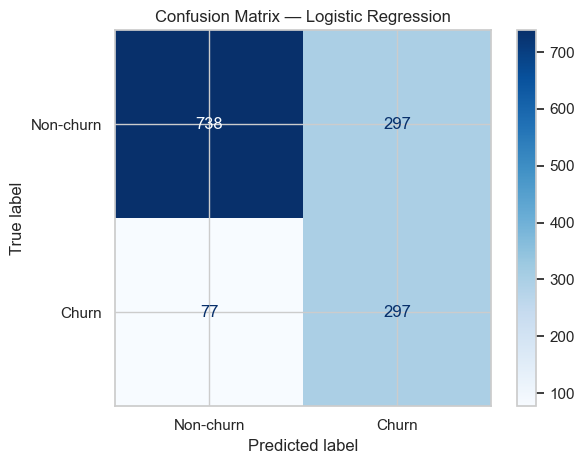


===== Decision Tree =====
              precision    recall  f1-score   support

   Non-churn       0.90      0.75      0.82      1035
       Churn       0.53      0.76      0.62       374

    accuracy                           0.76      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.76      0.77      1409



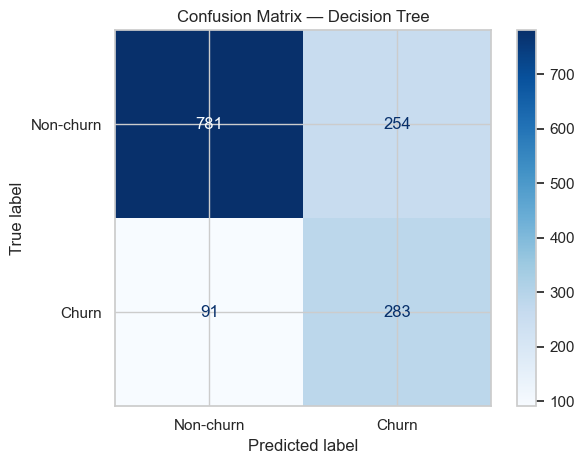


===== Random Forest =====
              precision    recall  f1-score   support

   Non-churn       0.90      0.77      0.83      1035
       Churn       0.54      0.76      0.63       374

    accuracy                           0.77      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.80      0.77      0.78      1409



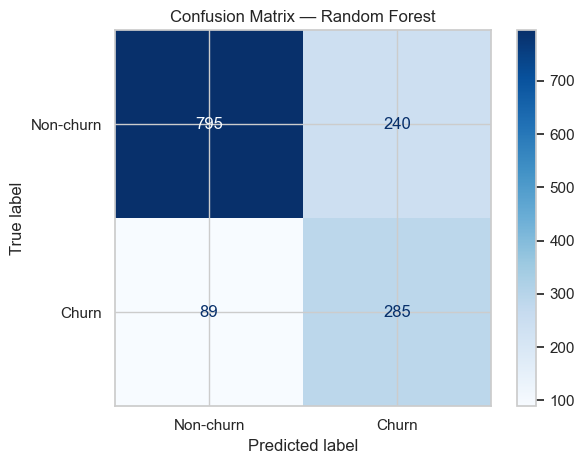

In [ ]:
# confusion matrix dan classification report setiap model
for model_name, y_pred in test_predictions.items():
    print(f"\n===== {model_name} =====")
    print(classification_report(
        y_test, y_pred,
        labels=[0, 1],
        target_names=["Non-churn", "Churn"],
        zero_division=0
    ))

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Non-churn", "Churn"]
    )
    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"Confusion Matrix — {model_name}")
    plt.tight_layout()
    plt.show()


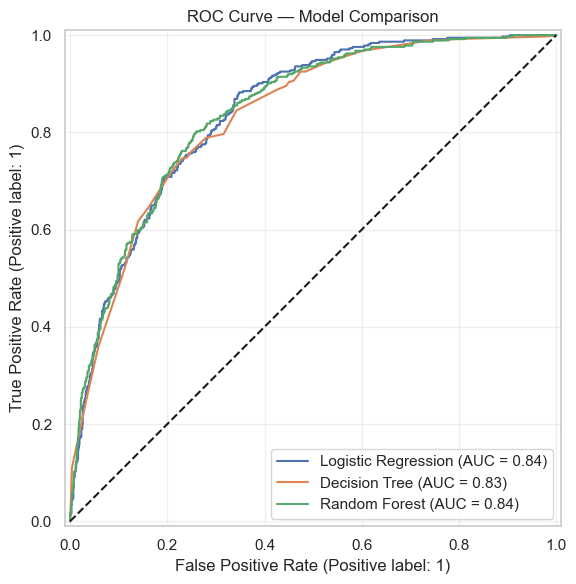

In [ ]:
# ROC curve
plt.figure(figsize=(8, 6))
ax = plt.gca()

for model_name, y_prob in test_probabilities.items():
    RocCurveDisplay.from_predictions(
        y_test, y_prob, name=model_name, ax=ax
    )

ax.plot([0, 1], [0, 1], "k--", label="Random classifier")
ax.set_title("ROC Curve — Model Comparison")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


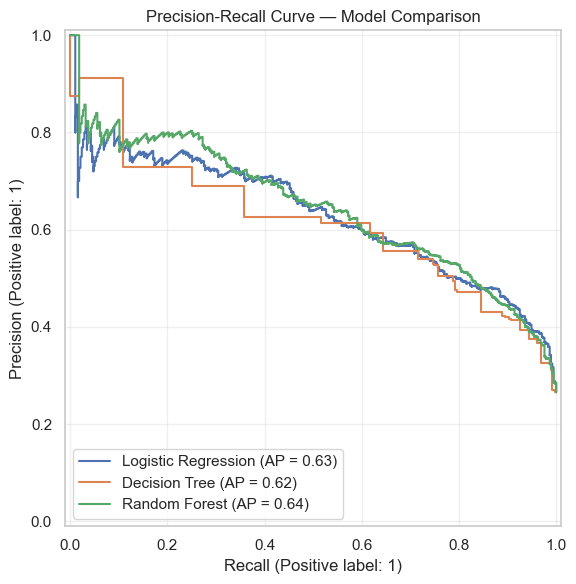

In [ ]:
# precision-recall curve
plt.figure(figsize=(8, 6))
ax = plt.gca()

for model_name, y_prob in test_probabilities.items():
    PrecisionRecallDisplay.from_predictions(
        y_test, y_prob, name=model_name, ax=ax
    )

ax.set_title("Precision-Recall Curve — Model Comparison")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Model dengan F1-score churn tertinggi pada test set: Random Forest


,Accuracy,Precision (Churn),Recall (Churn),F1 (Churn),ROC-AUC,PR-AUC (Average Precision)
Model,,,,,,
Random Forest,0.767,0.543,0.762,0.634,0.841,0.645


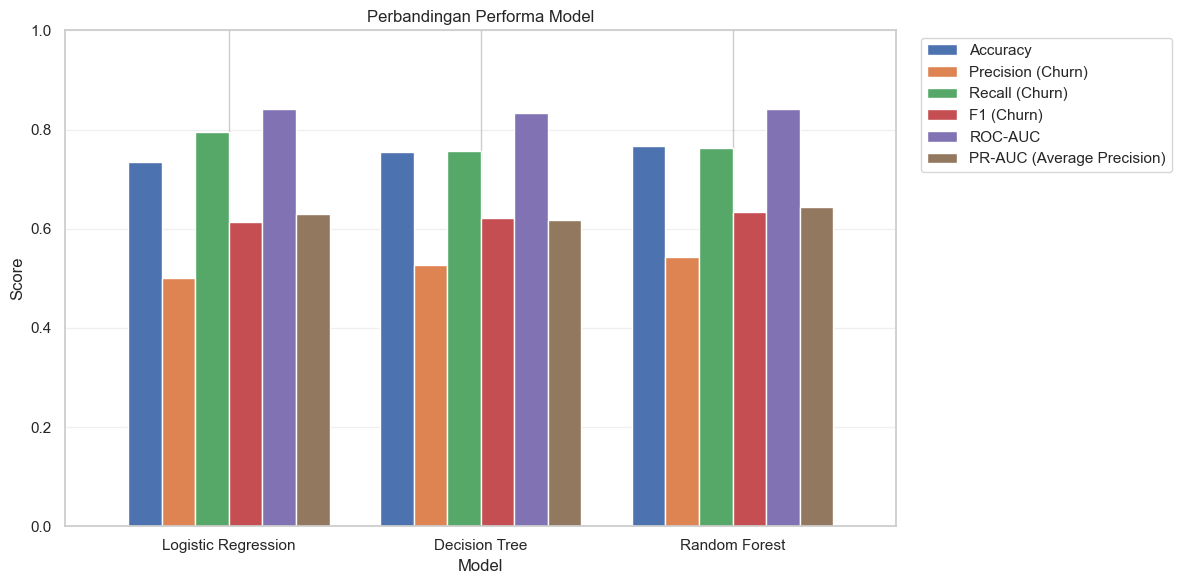

In [ ]:
# komparai dan pemilihan model terbaik dari hasil test
best_model_name = comparison_df["F1 (Churn)"].idxmax()
best_model = best_estimators[best_model_name]

print("Model dengan F1-score churn tertinggi pada test set:", best_model_name)
display(comparison_df.loc[[best_model_name]].style.format("{:.3f}"))

# Visualisasi ringkas metrik
metrics_to_plot = [
    "Accuracy", "Precision (Churn)", "Recall (Churn)",
    "F1 (Churn)", "ROC-AUC", "PR-AUC (Average Precision)"
]
comparison_df[metrics_to_plot].plot(
    kind="bar", figsize=(12, 6), ylim=(0, 1),
    rot=0, width=0.8
)
plt.title("Perbandingan Performa Model")
plt.ylabel("Score")
plt.xlabel("Model")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


,Feature,Importance Mean,Importance Std
14,Contract,0.036263,0.010388
7,InternetService,0.030579,0.006762
4,tenure,0.026030,0.006818
22,HasLongTermContract,0.013144,0.007010
18,TotalCharges,0.009832,0.004755
15,PaperlessBilling,0.008296,0.003614
19,TenureGroup,0.006595,0.004316
16,PaymentMethod,0.003075,0.003739
10,DeviceProtection,0.001907,0.001711
6,MultipleLines,0.001809,0.002180


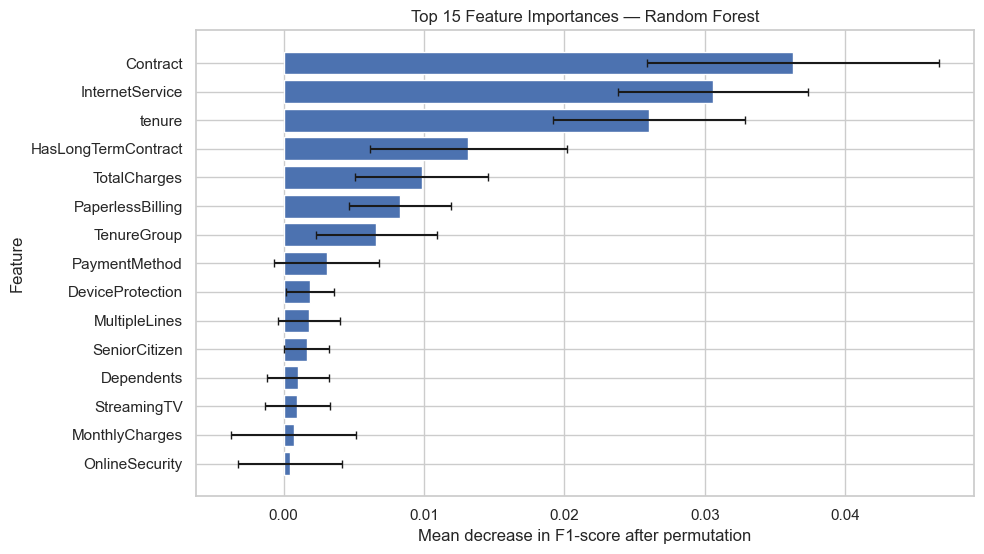

In [ ]:
# feature importance pada model terbaik
# dicari dengan permutation importance pada test set
# Metode ini mengukur penurunan skor ketika satu fitur diacak
# Untuk fitur kategorikal yang di-one-hot encode, permutasi dilakukan pada kolom asli sebelum preprocessing sehingga seluruh kategori dari satu fitur diperlakukan sebagai satu kesatuan.
perm_result = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="f1",
    n_repeats=20,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance Mean": perm_result.importances_mean,
    "Importance Std": perm_result.importances_std
}).sort_values("Importance Mean", ascending=False)

display(feature_importance)

top_n = min(15, len(feature_importance))
plot_data = feature_importance.head(top_n).sort_values("Importance Mean")

plt.figure(figsize=(10, max(5, top_n * 0.38)))
plt.barh(
    plot_data["Feature"],
    plot_data["Importance Mean"],
    xerr=plot_data["Importance Std"],
    capsize=3
)
plt.xlabel("Mean decrease in F1-score after permutation")
plt.ylabel("Feature")
plt.title(f"Top {top_n} Feature Importances — {best_model_name}")
plt.tight_layout()
plt.show()


Sugesti chatgpt untuk kesimpulan

Gunakan hasil tabel dan grafik untuk menuliskan kesimpulan, misalnya:
1. Model dengan F1-score churn dan ROC-AUC terbaik adalah [isi berdasarkan hasil].
2. Perhatikan trade-off precision dan recall. Recall tinggi berarti lebih banyak pelanggan churn berhasil terdeteksi, tetapi dapat meningkatkan false positive.
3. Periksa confusion matrix untuk memahami jumlah false negative (churn yang tidak terdeteksi) dan false positive (non-churn yang salah diprediksi churn).
4. Fitur dengan permutation importance tertinggi adalah [isi berdasarkan grafik]. Importance merupakan ukuran kontribusi prediktif, bukan kausalitas.
Catatan class imbalance: class_weight='balanced' telah diuji melalui GridSearchCV. Jika ingin mencoba SMOTE, lakukan hanya pada training fold menggunakan imblearn.pipeline.Pipeline agar oversampling tidak bocor ke validation/test set. Jangan melakukan SMOTE sebelum train-test split.
